<div style="background:#133044;color:white;padding:24px;border-radius:10px"><small>PLAYGROUND S6E11 · CREDIT CARD FRAUD</small><h1>Which signals rank fraud?</h1><p>Two ties and one extra point · Public ROC-AUC <b>0.95534</b></p></div>

Two predictions can agree on which transactions look risky and still disagree on the order of thousands of pairs. That disagreement is where an ensemble can change ROC-AUC. Here we follow the ranking twice: first in labeled transactions, where we can check individual features, then in test predictions, where Kaggle scored three small changes.

| Experiment | What you can reuse |
|---|---|
| Rank one feature at a time | Check whether its risk direction survives a holdout. |
| Compare two changes in predictions | Measure how much of one change follows the other. |
| Replay the three uploads | Recover the exact scored CSV and see how small the winning margin was. |

## 1 · Which features carry their ordering into a holdout?

Imagine drawing one fraudulent and one legitimate transaction. ROC-AUC measures how often the fraud receives the higher score, with half credit for a tie. That makes a single numeric column a useful first experiment. **Choose the direction on training rows.** Otherwise a noisy feature gets two chances to look good on the holdout.

The chart pairs training and holdout scores for the eight strongest training features. The table includes the weaker features too. A direction of −1 means smaller values looked riskier on the training split.

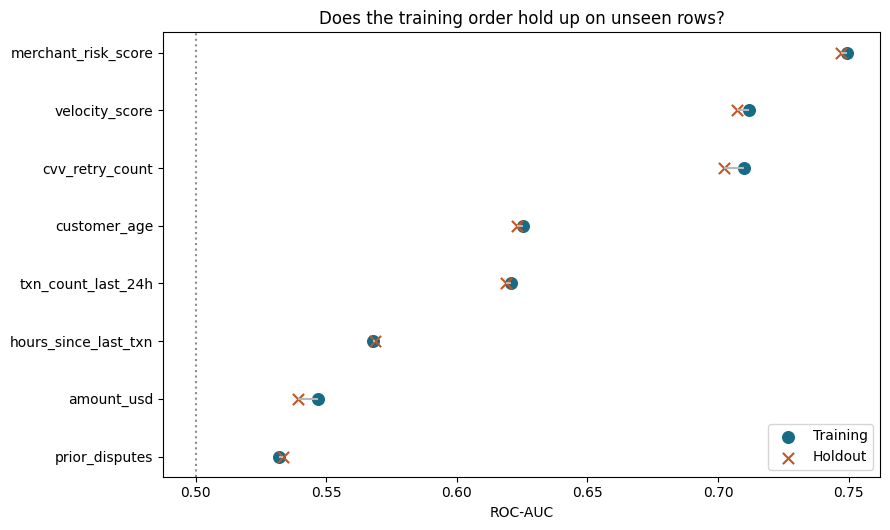

,feature,direction,training_auc,holdout_auc
8,merchant_risk_score,1,0.74957,0.74702
12,velocity_score,1,0.71200,0.70715
4,cvv_retry_count,1,0.71003,0.70223
3,customer_age,1,0.62525,0.62315
11,txn_count_last_24h,1,0.62082,0.61878
7,hours_since_last_txn,-1,0.56807,0.56865
1,amount_usd,1,0.54678,0.53905
9,prior_disputes,1,0.53174,0.53348
5,day_of_week,1,0.50819,0.50797
6,distance_from_home_km,1,0.50570,0.49838


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

root = Path('/kaggle/input')
paths = [p for p in root.rglob('train.csv') if 'playground-series-s6e11' in str(p)]
assert len(paths) == 1, paths
train = pd.read_csv(paths[0])
y = train.pop('is_fraud')
assert set(y.unique()) == {0, 1}
a, b = train_test_split(np.arange(len(y)), test_size=.25, random_state=42, stratify=y)
rows = []
for col in train.select_dtypes(include='number').columns.difference(['id']):
    x = train[col].replace([np.inf, -np.inf], np.nan)
    median = x.iloc[a].median()
    if pd.isna(median) or x.iloc[a].nunique() < 2:
        continue
    x = x.fillna(median)
    raw = roc_auc_score(y.iloc[a], x.iloc[a])
    sign = 1 if raw >= .5 else -1
    rows.append((col, sign, max(raw, 1-raw), roc_auc_score(y.iloc[b], sign*x.iloc[b])))
scores = pd.DataFrame(rows, columns=['feature','direction','training_auc','holdout_auc']).sort_values('training_auc', ascending=False)
assert len(scores), 'No eligible numeric feature'
top = scores.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, max(3, .55*len(top)+1)))
ax.hlines(top.feature, top.training_auc, top.holdout_auc, color='0.72')
ax.scatter(top.training_auc, top.feature, label='Training', color='#176b85', s=70)
ax.scatter(top.holdout_auc, top.feature, label='Holdout', color='#c35422', marker='x', s=65)
ax.axvline(.5, color='0.55', linestyle=':')
ax.set(xlabel='ROC-AUC', title='Does the training order hold up on unseen rows?')
ax.legend()
fig.tight_layout()
plt.show()
display(scores.round(5))


## 2 · Separate the latest ranking change into two parts

Merchant risk scored **0.74702** alone on holdout, velocity **0.70715**, and amount **0.53905**. These figures describe individual features. The ensemble below starts from existing multivariate predictions. Its public score comes from different rows.

Call the leading file **N**, its previous version **M**, and the fusion file **F**. Align all three by transaction ID. Convert each to percentile ranks and take the logit so that differences near the extremes receive more weight.

| Quantity | Calculation | How to read it |
|---|---|---|
| Latest move | d = N − M | Which transactions rose or fell in the latest version? |
| Comparison move | e = F − M | Where does the fusion file disagree with the same parent? |
| Shared component | βe, with β = (d · e)/(e · e) | The part of d explained by moving along e. |
| Residual | r = d − βe | The part perpendicular to e on this test set. |

**The candidate is N + 0.5r.** For example, when both moves raise the same row, the projection can reduce the extra push that row receives. Orthogonality describes a geometric relationship between predictions. Its value for scoring has to be measured.

In [2]:
from scipy.special import logit
from scipy.stats import rankdata
import hashlib
import numpy as np
import pandas as pd
from pathlib import Path
import kagglehub
from IPython.display import display, Markdown
sample = pd.read_csv(next(p for p in Path('/kaggle/input').rglob('sample_submission.csv') if 'playground-series-s6e11' in str(p)))
def ranks(x):
    return (rankdata(x) - .5) / len(x)
def read_scores(handle, filename):
    root = Path(kagglehub.notebook_output_download(handle))
    path, = root.rglob(filename)
    f = pd.read_csv(path)
    assert f.id.is_unique and sample.id.is_unique and len(f)==len(sample)
    v = f.set_index('id').loc[sample.id,'is_fraud'].to_numpy()
    assert np.isfinite(v).all()
    expected = {('goodpjw2008','submission.csv'):'4809c90b7df73471',('goodpjw2008','submission_step_m.csv'):'bed323097b1d78a8',('malyshevdanil','submission.csv'):'87f7b19b16e24e76'}
    assert hashlib.sha256(path.read_bytes()).hexdigest().startswith(expected[(handle.split('/')[0],filename)]), 'Upstream file changed'
    return logit(ranks(v))
ladder = 'goodpjw2008/s6e11-board-model-realmlp-lb-0-95533'
fusion = 'malyshevdanil/fraud-signal-lab-gpt-2-and-glm-fusion'
n = read_scores(ladder,'submission.csv')
m = read_scores(ladder,'submission_step_m.csv')
f = read_scores(fusion,'submission.csv')
step = n-m
offset = f-m
assert step@step > 0 and offset@offset > 0
residual = step - offset * ((step@offset)/(offset@offset))
variants = {'extend25': n+.25*step, 'fusion15': .85*n+.15*f, 'residual50': n+.5*residual}
out = Path('/kaggle/working')
for tag,v in variants.items():
    pred = sample[['id']].assign(is_fraud=ranks(v))
    p = out / (tag+'.csv')
    pred.to_csv(p,index=False)
    reread = pd.read_csv(p)
    assert reread.columns.tolist()==sample.columns.tolist() and reread.id.equals(sample.id)
    assert reread.is_fraud.between(0,1).all() and len(reread)==299984
    print('CHECKED',tag,len(pred),hashlib.sha256(p.read_bytes()).hexdigest()[:16])


CHECKED extend25 299984 fcf9437f2c09d6ac
CHECKED fusion15 299984 73bf40b693717217
CHECKED residual50 299984 f3039b167e0dfdca


## 3 · What the three uploads actually earned

| Candidate | Public ROC-AUC | Change from N |
|---|---:|---:|
| Extend the full move by 25% | 0.95533 | 0.00000 |
| Give the fusion file 15% weight | 0.95533 | 0.00000 |
| Extend half the residual | **0.95534** | **+0.00001** |

The notebook submission independently reproduced the winning file upload's displayed score. Both used the same test predictions and public labels, so this checks reproducibility. The private-set effect is unknown.

**Try this on your own ensemble.** Use aligned out-of-fold predictions for all three inputs. Estimate the projection and choose the step size on development folds, freeze both, then compare AUC on a held-out fold. Record every attempted step, including ties.

submission.csv SHA-256: f3039b167e0dfdca0161b95abb2e36ad0e694c0790384adb1268f527cee4ae56


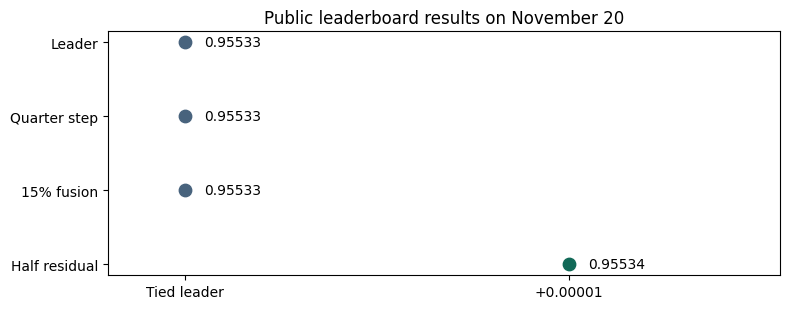

In [3]:
from shutil import copyfile
import hashlib
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

winner = Path('/kaggle/working/residual50.csv')
assert hashlib.sha256(winner.read_bytes()).hexdigest().startswith('f3039b167e0dfdca')
output = winner.with_name('submission.csv')
copyfile(winner, output)
assert output.read_bytes() == winner.read_bytes()
print('submission.csv SHA-256:', hashlib.sha256(output.read_bytes()).hexdigest())
labels = ['Leader', 'Quarter step', '15% fusion', 'Half residual']
auc = [0.95533, 0.95533, 0.95533, 0.95534]
fig, ax = plt.subplots(figsize=(8, 3.2))
for i,(label,value) in enumerate(zip(labels,auc)):
    gain = round((value-auc[0])*100000)
    ax.scatter(gain,i,color='#116957' if gain else '#48637d',s=80)
    ax.text(gain+.05,i,f'{value:.5f}',va='center')
ax.set_yticks(range(4), labels)
ax.set_xticks([0,1],['Tied leader','+0.00001'])
ax.set_xlim(-.2,1.55)
ax.invert_yaxis()
ax.set_title('Public leaderboard results on November 20')
fig.tight_layout()
plt.show()


## Credits and references
- [goodpjw2008, Board Model + RealMLP](https://www.kaggle.com/code/goodpjw2008/s6e11-board-model-realmlp-lb-0-95533?scriptVersionId=371822628) — version 16 supplies the leader and step M. Its credits document the upstream model authors and ensemble components.
- [Malyshev Danil, Fraud Signal Lab](https://www.kaggle.com/code/malyshevdanil/fraud-signal-lab-gpt-2-and-glm-fusion) — predictions defining the comparison direction.
- [Areeb Ali, Split, Then Push](https://www.kaggle.com/code/areebbb/s6e11-split-then-push-lb-0-95431) — earlier residual-step experiment.
- [Kaggle S6E11](https://www.kaggle.com/competitions/playground-series-s6e11) — data and evaluation. [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html) — ROC-AUC implementation.